In [148]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

In [149]:
df = pd.read_csv("project_risk_raw_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (4000, 51)


,Project_ID,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Methodology_Used,Team_Experience_Level,Past_Similar_Projects,External_Dependencies_Count,Change_Request_Frequency,Project_Phase,Requirement_Stability,Team_Turnover_Rate,Vendor_Reliability_Score,Historical_Risk_Incidents,Communication_Frequency,Regulatory_Compliance_Level,Technology_Familiarity,Geographical_Distribution,Stakeholder_Engagement_Level,Schedule_Pressure,Budget_Utilization_Rate,Executive_Sponsorship,Funding_Source,Market_Volatility,Integration_Complexity,Resource_Availability,Priority_Level,Organizational_Change_Frequency,Cross_Functional_Dependencies,Previous_Delivery_Success_Rate,Technical_Debt_Level,Project_Manager_Experience,Org_Process_Maturity,Data_Security_Requirements,Key_Stakeholder_Availability,Tech_Environment_Stability,Contract_Type,Resource_Contention_Level,Industry_Volatility,Client_Experience_Level,Change_Control_Maturity,Risk_Management_Maturity,Team_Colocation,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Seasonal_Risk_Factor,Risk_Level
0,PROJ_0001,Construction,32,1526276.55,32,9.70,16,Waterfall,Senior,3,3,1.05,Planning,Moderate,0.16,0.84,2,1.90,Medium,Expert,4,Medium,0.0,0.82,Moderate,Government,0.55,2.66,0.98,Medium,0.29,6,0.80,0.00,Mid-level PM,Managed,Medium,Limited,NaN,Time & Materials,High,Extreme,First-time,Basic,Basic,Fully Colocated,Good,10,5,1.0,High
1,PROJ_0002,Manufacturing,2,390790.15,9,2.72,9,Kanban,Mixed,0,2,2.61,Execution,Moderate,0.42,0.79,2,2.65,High,Familiar,5,Excellent,0.0,0.76,Weak,External,0.29,2.45,0.95,Low,0.50,3,0.73,0.00,Mid-level PM,Optimizing,Low,Excellent,NaN,Cost-Plus,Low,Stable,Occasional,Advanced,Formal,Fully Remote,Poor,9,3,1.0,Low
2,PROJ_0003,Manufacturing,2,246674.76,6,2.04,7,Agile,Mixed,1,0,0.83,Initiation,Stable,0.55,0.89,2,1.87,Medium,Familiar,3,Excellent,0.0,1.17,Strong,Internal,0.15,5.57,0.79,High,2.71,2,0.91,0.00,Mid-level PM,Ad-hoc,Medium,Moderate,NaN,Cost-Plus,High,Stable,Regular,None,None,Hybrid,Good,5,1,1.0,Medium
3,PROJ_0004,IT,12,1427830.63,17,7.54,16,Scrum,Mixed,0,5,2.42,Initiation,Moderate,0.33,0.84,1,1.36,Low,Familiar,5,Medium,0.1,0.73,Moderate,Mixed,0.74,7.49,0.52,Critical,0.74,5,0.71,0.43,Certified PM,Managed,Strict,Good,Mixed,Hybrid,High,Extreme,Strategic,Formal,Basic,Hybrid,Basic,12,6,1.1,High
4,PROJ_0005,Construction,24,1696746.64,24,6.68,17,Hybrid,Junior,0,2,0.16,Execution,Stable,0.36,0.86,1,1.02,Critical,Expert,2,Low,0.0,0.60,Moderate,Government,0.19,1.64,0.58,Medium,0.56,6,0.83,0.00,Certified PM,Defined,Medium,Moderate,NaN,Cost-Plus,High,Moderate,Occasional,Basic,None,Partially Colocated,Basic,9,6,1.0,High


In [150]:
df = df.drop(columns=["Project_Type","Methodology_Used","Vendor_Reliability_Score","Communication_Frequency","Regulatory_Compliance_Level","Geographical_Distribution","Integration_Complexity","Organizational_Change_Frequency","Cross_Functional_Dependencies","Technical_Debt_Level","Org_Process_Maturity","Data_Security_Requirements","Key_Stakeholder_Availability","Tech_Environment_Stability","Contract_Type","Industry_Volatility","Change_Control_Maturity", "Team_Colocation","Seasonal_Risk_Factor"])
df = df.drop(columns=["Project_ID","Project_Manager_Experience", "Client_Experience_Level", "Risk_Management_Maturity", "Documentation_Quality"])
df = df.drop(columns=["Requirement_Stability","Team_Turnover_Rate","Stakeholder_Engagement_Level","Funding_Source","Executive_Sponsorship"])

In [151]:
df.head()

,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Team_Experience_Level,Past_Similar_Projects,External_Dependencies_Count,Change_Request_Frequency,Project_Phase,Historical_Risk_Incidents,Technology_Familiarity,Schedule_Pressure,Budget_Utilization_Rate,Market_Volatility,Resource_Availability,Priority_Level,Previous_Delivery_Success_Rate,Resource_Contention_Level,Project_Start_Month,Current_Phase_Duration_Months,Risk_Level
0,32,1526276.55,32,9.70,16,Senior,3,3,1.05,Planning,2,Expert,0.0,0.82,0.55,0.98,Medium,0.80,High,10,5,High
1,2,390790.15,9,2.72,9,Mixed,0,2,2.61,Execution,2,Familiar,0.0,0.76,0.29,0.95,Low,0.73,Low,9,3,Low
2,2,246674.76,6,2.04,7,Mixed,1,0,0.83,Initiation,2,Familiar,0.0,1.17,0.15,0.79,High,0.91,High,5,1,Medium
3,12,1427830.63,17,7.54,16,Mixed,0,5,2.42,Initiation,1,Familiar,0.1,0.73,0.74,0.52,Critical,0.71,High,12,6,High
4,24,1696746.64,24,6.68,17,Junior,0,2,0.16,Execution,1,Expert,0.0,0.60,0.19,0.58,Medium,0.83,High,9,6,High


In [152]:
null_counts = df.isna().sum().sort_values(ascending=False)
null_counts

Team_Size                         0
Project_Budget_USD                0
Current_Phase_Duration_Months     0
Project_Start_Month               0
Resource_Contention_Level         0
Previous_Delivery_Success_Rate    0
Priority_Level                    0
Resource_Availability             0
Market_Volatility                 0
Budget_Utilization_Rate           0
Schedule_Pressure                 0
Technology_Familiarity            0
Historical_Risk_Incidents         0
Project_Phase                     0
Change_Request_Frequency          0
External_Dependencies_Count       0
Past_Similar_Projects             0
Team_Experience_Level             0
Stakeholder_Count                 0
Complexity_Score                  0
Estimated_Timeline_Months         0
Risk_Level                        0
dtype: int64

In [153]:
# Show all columns in DataFrame display
pd.set_option("display.max_columns", None)

df.head()

,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Team_Experience_Level,Past_Similar_Projects,External_Dependencies_Count,Change_Request_Frequency,Project_Phase,Historical_Risk_Incidents,Technology_Familiarity,Schedule_Pressure,Budget_Utilization_Rate,Market_Volatility,Resource_Availability,Priority_Level,Previous_Delivery_Success_Rate,Resource_Contention_Level,Project_Start_Month,Current_Phase_Duration_Months,Risk_Level
0,32,1526276.55,32,9.70,16,Senior,3,3,1.05,Planning,2,Expert,0.0,0.82,0.55,0.98,Medium,0.80,High,10,5,High
1,2,390790.15,9,2.72,9,Mixed,0,2,2.61,Execution,2,Familiar,0.0,0.76,0.29,0.95,Low,0.73,Low,9,3,Low
2,2,246674.76,6,2.04,7,Mixed,1,0,0.83,Initiation,2,Familiar,0.0,1.17,0.15,0.79,High,0.91,High,5,1,Medium
3,12,1427830.63,17,7.54,16,Mixed,0,5,2.42,Initiation,1,Familiar,0.1,0.73,0.74,0.52,Critical,0.71,High,12,6,High
4,24,1696746.64,24,6.68,17,Junior,0,2,0.16,Execution,1,Expert,0.0,0.60,0.19,0.58,Medium,0.83,High,9,6,High


In [154]:
# Encode Risk_Level to numeric for correlation
risk_map = {"Low": 1, "Medium": 2, "High": 3, "Critical": 4}
df["Risk_Level_Numeric"] = df["Risk_Level"].map(risk_map)

# Calculate correlation
correlation = df[["Risk_Level_Numeric", "Budget_Utilization_Rate"]].corr()
print("Correlation between Risk Level and Budget Utilization Rate:")
print(correlation)

Correlation between Risk Level and Budget Utilization Rate:
                         Risk_Level_Numeric  Budget_Utilization_Rate
Risk_Level_Numeric                 1.000000                 0.049738
Budget_Utilization_Rate            0.049738                 1.000000


In [155]:
df = df.drop("Risk_Level", axis=1)

In [156]:
# Show all remaining columns after dropping
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Remaining columns after dropping:")
print(df.columns.tolist())
print(f"\nTotal columns: {len(df.columns)}")
print(f"Shape: {df.shape}")

Remaining columns after dropping:
['Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'Stakeholder_Count', 'Team_Experience_Level', 'Past_Similar_Projects', 'External_Dependencies_Count', 'Change_Request_Frequency', 'Project_Phase', 'Historical_Risk_Incidents', 'Technology_Familiarity', 'Schedule_Pressure', 'Budget_Utilization_Rate', 'Market_Volatility', 'Resource_Availability', 'Priority_Level', 'Previous_Delivery_Success_Rate', 'Resource_Contention_Level', 'Project_Start_Month', 'Current_Phase_Duration_Months', 'Risk_Level_Numeric']

Total columns: 22
Shape: (4000, 22)


In [157]:
print(df.corr(numeric_only=True)["Risk_Level_Numeric"].sort_values(ascending=False))

Risk_Level_Numeric                1.000000
Complexity_Score                  0.350977
Estimated_Timeline_Months         0.278886
External_Dependencies_Count       0.266652
Project_Budget_USD                0.185820
Team_Size                         0.170922
Current_Phase_Duration_Months     0.164627
Stakeholder_Count                 0.164476
Market_Volatility                 0.100477
Budget_Utilization_Rate           0.049738
Project_Start_Month              -0.002682
Schedule_Pressure                -0.002923
Historical_Risk_Incidents        -0.005842
Change_Request_Frequency         -0.013041
Resource_Availability            -0.092213
Past_Similar_Projects            -0.154545
Previous_Delivery_Success_Rate   -0.161859
Name: Risk_Level_Numeric, dtype: float64


In [158]:
TARGET = "Risk_Level_Numeric"

y = df[TARGET]
X = df.drop(columns=["Risk_Level_Numeric"])

In [159]:
cat_cols = X.select_dtypes(include=["object"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

print("Categorical columns:", list(cat_cols))
print("Numeric columns:", list(num_cols))


Categorical columns: ['Team_Experience_Level', 'Project_Phase', 'Technology_Familiarity', 'Priority_Level', 'Resource_Contention_Level']
Numeric columns: ['Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'Stakeholder_Count', 'Past_Similar_Projects', 'External_Dependencies_Count', 'Change_Request_Frequency', 'Historical_Risk_Incidents', 'Schedule_Pressure', 'Budget_Utilization_Rate', 'Market_Volatility', 'Resource_Availability', 'Previous_Delivery_Success_Rate', 'Project_Start_Month', 'Current_Phase_Duration_Months']


In [160]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [161]:
onehot_cols = ["Team_Experience_Level", "Project_Phase"]

ordinal_cols = [
    "Technology_Familiarity",
    "Priority_Level",
    "Resource_Contention_Level"
]

tech_order = ["New", "Familiar", "Expert"]
priority_order = ["Low", "Medium", "High", "Critical"]
resource_order = ["Low", "Medium", "High"]


In [162]:
preprocess = ColumnTransformer(
    transformers=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
        ("ordinal", OrdinalEncoder(categories=[
            tech_order,
            priority_order,
            resource_order
        ]), ordinal_cols),
    ],
    remainder="passthrough"
)


In [163]:
preprocess.fit(X_train)


ColumnTransformer(remainder='passthrough',
                  transformers=[('onehot',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Team_Experience_Level', 'Project_Phase']),
                                ('ordinal',
                                 OrdinalEncoder(categories=[['New', 'Familiar',
                                                             'Expert'],
                                                            ['Low', 'Medium',
                                                             'High',
                                                             'Critical'],
                                                            ['Low', 'Medium',
                                                             'High']]),
                                 ['Technology_Familiarity', 'Priority_Level',
                                  'Resource_Contention_Level'])])

In [164]:
X_train_encoded = preprocess.transform(X_train)

In [165]:
X_test_encoded = preprocess.transform(X_test)

In [166]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=2000)

clf.fit(X_train_encoded, y_train)

LogisticRegression(max_iter=2000)

In [167]:
model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", clf)
])

In [168]:
# Predictions
y_pred = clf.predict(X_test_encoded)

# Probabilities
probs = clf.predict_proba(X_test_encoded)[:, 1]

In [169]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.00      0.00      0.00       161
           2       0.35      1.00      0.52       279
           3       0.00      0.00      0.00       207
           4       0.00      0.00      0.00       153

    accuracy                           0.35       800
   macro avg       0.09      0.25      0.13       800
weighted avg       0.12      0.35      0.18       800

Confusion matrix:
 [[  0 161   0   0]
 [  0 279   0   0]
 [  0 207   0   0]
 [  0 153   0   0]]


c:\Users\maria\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\maria\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\maria\anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [170]:
print("Min probability:", probs.min())
print("Max probability:", probs.max())
print("Mean probability:", probs.mean())

Min probability: 0.25778130893087875
Max probability: 0.41556224419680227
Mean probability: 0.3070594820913019


In [171]:
import sys
print(sys.executable)

c:\Users\maria\anaconda3\python.exe


In [172]:
from xgboost import XGBClassifier

In [173]:
y_train=y_train-1
y_test=y_test-1

In [174]:

from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", XGBClassifier(
        objective="multi:softprob",
        eval_metric="mlogloss",
        num_class=4,
        random_state=42,
        n_estimators=100,
 
    ))
])

xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Team_Experience_Level',
                                                   'Project_Phase']),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['New',
                                                                              'Familiar',
                                                                              'Expert'],
                                                                             ['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Critical'],
                                                                             ['Low',
                                                                              'Medium',
                                                                              'High']]),
                                                  ['Technology_Familiarity',
                                                   'Priority_Level',
                                                   'R...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None, num_class=4,
                               num_parallel_tree=None, ...))])

In [175]:
probs = xgb_model.predict_proba(X_test)
print(probs[:10])
print("Minimum probability:", probs.min())
print("Maximum probability:", probs.max())

[[1.6255863e-01 5.6790185e-01 2.1015169e-01 5.9387859e-02]
 [4.4410929e-02 2.4436557e-01 5.6501931e-01 1.4620420e-01]
 [4.3069899e-01 3.9592758e-01 1.5494163e-01 1.8431762e-02]
 [5.9847645e-03 7.8828678e-02 7.1098465e-01 2.0420189e-01]
 [5.2428490e-01 2.6449296e-01 1.9553977e-01 1.5682340e-02]
 [9.9622503e-02 5.7181025e-01 2.4429303e-01 8.4274225e-02]
 [4.2825856e-04 1.6273864e-02 7.7517495e-02 9.0578038e-01]
 [1.4713037e-01 3.3233997e-01 5.1034153e-01 1.0188110e-02]
 [2.1988637e-04 2.1362808e-02 1.0143932e-01 8.7697792e-01]
 [1.1839001e-01 4.5397338e-01 3.6690342e-01 6.0733203e-02]]
Minimum probability: 5.384502e-06
Maximum probability: 0.9961479


Confusion Matrix:
[[ 70  69  20   2]
 [ 49 128  75  27]
 [ 13  95  67  32]
 [  3  26  58  66]]


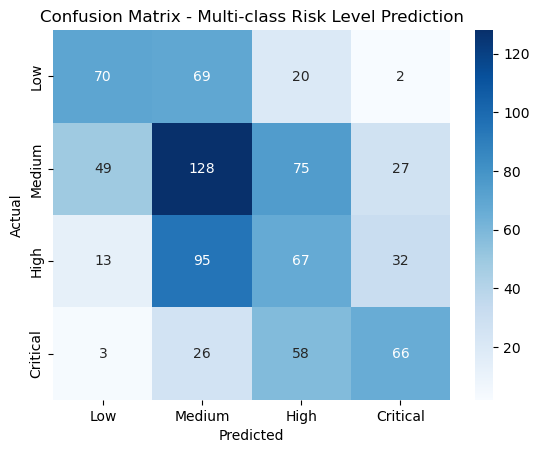

In [176]:
# Get predictions (direct class labels for multi-class)
y_pred = xgb_model.predict(X_test)

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0,1,2,3])
print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Low', 'Medium', 'High', 'Critical'], yticklabels=['Low', 'Medium', 'High', 'Critical'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Multi-class Risk Level Prediction")
plt.show()

In [177]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1-score:", f1_score(y_test, y_pred, average="weighted"))
print("Classification Report:\n", classification_report(y_test, y_pred))

Precision: 0.4229201104855818
Recall: 0.41375
F1-score: 0.41609449798202996
Classification Report:
               precision    recall  f1-score   support

           0       0.52      0.43      0.47       161
           1       0.40      0.46      0.43       279
           2       0.30      0.32      0.31       207
           3       0.52      0.43      0.47       153

    accuracy                           0.41       800
   macro avg       0.44      0.41      0.42       800
weighted avg       0.42      0.41      0.42       800

